In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
from jax.flatten_util import ravel_pytree
import optax
import matplotlib.pyplot as plt
from matplotlib import ticker
import os
from tqdm import tqdm

from src.bnn import Problem
from src.gsbl import GSBLBNN

from src.scalar2d_dg import ScalarDG2D, KPP, burgers2d
from dataclasses import dataclass

In [2]:
print("jax", jax.__version__, "| device:", jax.devices()[0])

jax 0.11.0 | device: cpu:0


In [3]:
import matplotlib as mpl
import scienceplots
plt.style.use(['science', 'nature', 'grid'])
from cycler import cycler
mpl.rcParams['axes.prop_cycle'] = cycler(color=['b', 'g', 'r', 'c', 'm', 'y', 'k'])

In [4]:
mpl.rcParams['axes.labelsize'] = 9
mpl.rcParams['font.size'] = 9
mpl.rcParams['xtick.labelsize'] = 9
mpl.rcParams['ytick.labelsize'] = 9

## Configuration

In [5]:
NX = NY = 64                # cells per direction; see the cost table above
REFINE_OBSERVATIONS = 4
T_END = 1.0
CFL = 0.9

M = 484                     # observations, on a 16 x 16 lattice
NOISE = 0.5                 # 4.9% of the data range, cf. 0.05 on 1D Burgers
# ToDo: Check the noise level and maybe normalize everything to [0, 1] then use NOISE = 0.05
SEED = 42

U_LO, U_HI = 0.25 * jnp.pi, 3.5 * jnp.pi   # network output is mapped affinely onto this

# flux=burgers2d(u_ref=...) switches the equation and nothing else.
solver = ScalarDG2D(flux=KPP, nx=NX, ny=NY, t_end=T_END, cfl=CFL,
                    bc="transmissive", remat=True)
solver_fine = ScalarDG2D(
    flux=KPP, nx=NX*REFINE_OBSERVATIONS, ny=NY*REFINE_OBSERVATIONS, t_end=T_END, cfl=CFL,
    bc="transmissive", remat=True
)

XY_NODES_J = jnp.asarray(solver.xy_flat)                 # (4*NX*NY, 2) network input
OBS_IDX, x_obs, y_obs_pts = solver.observation_indices(M)
XY_NODES_J_fine = jnp.asarray(solver_fine.xy_flat)                 # (4*NX*NY, 2) network input
OBS_IDX_fine, x_obs_fine, y_obs_pts_fine = solver_fine.observation_indices(M)

print(f"{solver.nx}x{solver.ny} cells, {solver.n_dofs} dofs, flux = {solver.flux.name}")
print(f"dt = {solver.dt:.3e}, n_steps = {solver.n_steps}")

64x64 cells, 16384 dofs, flux = kpp
dt = 9.346e-03, n_steps = 107


## Forward problem: truth and observations

In [6]:
ic_true = solver.disk()          # 14 pi / 4 on the unit disk, pi / 4 outside



solver.solve(ic_true).block_until_ready()      # compile before timing
d_true = solver.solve(ic_true)
d_true.block_until_ready()

u_init = jnp.asarray(solver.image(solver.limit(ic_true)))
u_sol = jnp.asarray(solver.image(d_true))

In [7]:
ic_true_fine = solver_fine.disk()          # 14 pi / 4 on the unit disk, pi / 4 outside


solver_fine.solve(ic_true_fine).block_until_ready()      # compile before timing
d_true = solver_fine.solve(ic_true_fine)
d_true.block_until_ready()

u_init_fine = jnp.asarray(solver_fine.image(solver_fine.limit(ic_true_fine)))
u_sol_fine = jnp.asarray(solver_fine.image(d_true))

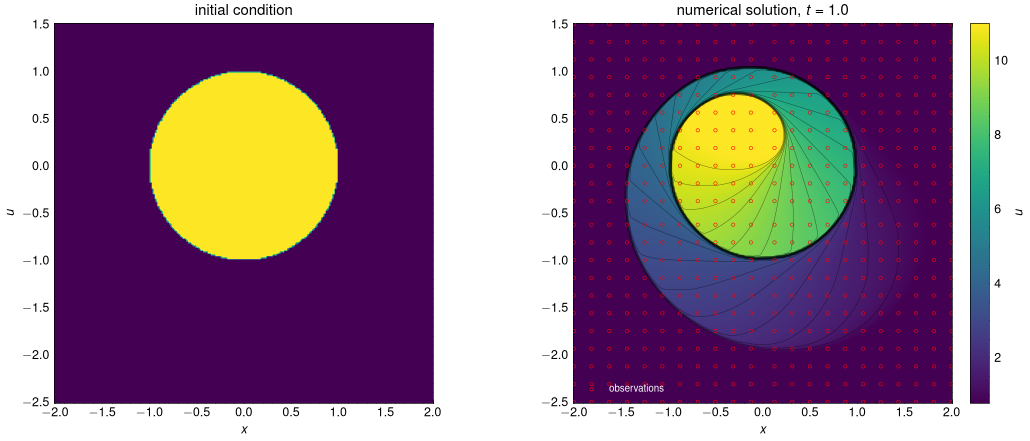

In [8]:
y_obs = jnp.asarray(u_sol_fine.ravel()[OBS_IDX], dtype=jnp.float32) \
        + NOISE * jr.normal(jr.PRNGKey(SEED), (M,), dtype=jnp.float32)

xs_fine, ys_fine = solver_fine.x_sample, solver_fine.y_sample
levels = jnp.linspace(U_LO, U_HI, 31)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, field, title in (
    (axs[0], u_init_fine, "initial condition"),
    (axs[1], u_sol_fine, f"numerical solution, $t = {T_END}$")):
    m = ax.pcolormesh(
        xs_fine, ys_fine, field, cmap="viridis", shading="nearest",
        vmin=U_LO, vmax=U_HI, rasterized=True
    )
    ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_title(title)
axs[0].set_ylabel("$u$")
axs[1].contour(
    solver_fine.cell_x, solver_fine.cell_y, jnp.asarray(solver_fine.cell_mean(d_true)),
    levels=levels, colors="k", linewidths=0.3, alpha=0.6
)
axs[1].scatter(
    x_obs, y_obs_pts, facecolors="none", edgecolors="red",
    s=6, linewidths=0.4, zorder=5, label="observations"
)
axs[1].legend(loc="lower left", frameon=False, labelcolor="white")
fig.colorbar(m, ax=axs, fraction=0.03, pad=0.01, label="$u$")
plt.show()

## Inverse problem

In [9]:
net_arc_identifier = 1 # This is the one working the best

if net_arc_identifier == 0:
    width = [2, 64, 64, 64, 64, 1]
elif net_arc_identifier == 1:
    width = [2, 128, 128, 128, 128, 1]
elif net_arc_identifier == 2:
    width = [2, 80, 80, 1000, 1]
elif net_arc_identifier == 3:
    width = [2, 100, 100, 1200, 1]
elif net_arc_identifier == 4:
    width = [2, 256, 256, 256, 256, 1]
activation = jax.nn.tanh

N_EPOCHS_ADAM = 2_500
N_EPOCHS_LBFGS = 12_500
n_inner = 10
lr_schedule = 1e-3

optimizer_pretraining = optax.contrib.muon(lr_schedule)

vartheta1 = 10.0
kappa = 10.0
c_bias = 2.0
r = -1.0
beta = 1.0
initializer = 'GG'

N_ENSEMBLES = 10
N_ENSEMBLES_THROW_AWAY = 1

base_dir = f'out/KPP2D/NX{NX}_M{M}_vartheta1_{vartheta1}_beta_{beta}_kappa_{kappa}_net_arc_{net_arc_identifier}'

models = []
for i in range(N_ENSEMBLES):
    model = GSBLBNN(
        width=width, activation=activation, seed=SEED + i * 1_000,
        optimizer_pretraining=optimizer_pretraining,
        n_epochs_pre_training=N_EPOCHS_ADAM, n_epochs_lbfgs=N_EPOCHS_LBFGS,
        vartheta1=vartheta1, kappa=kappa, c_bias=c_bias,
        shared_bias=True, n_inner=n_inner,
        r=r, beta=beta,
        initializer=initializer,
    )
    models.append(model)
print(f"{model.K} parameters")

50049 parameters


In [10]:
@dataclass(frozen=True)
class InverseKPPProblem(Problem):
    """y_obs = observe(solve(u_net(x, y))) + noise * eps.

    The network is evaluated on the flattened (4*NX*NY, 2) node coordinates and
    reshaped to the solver's (NY, NX, 2, 2) layout, then mapped affinely onto
    [U_LO, U_HI]. Because the nodes either side of an interface share a coordinate,
    a continuous network produces a continuous initial condition -- and the truth
    here is a disk-shaped jump, which is exactly what the GSBL prior is meant to
    let the network resolve.
    """

    def apply(self, net):
        u = jax.vmap(net)(XY_NODES_J).reshape(NY, NX, 2, 2)
        ic = (U_LO + (U_HI - U_LO) * u).astype(jnp.float32)
        return solver.image(solver.solve(ic)).ravel()[OBS_IDX]


prob = InverseKPPProblem(x_disc=XY_NODES_J, y_obs=y_obs, noise=NOISE)

In [11]:
for model in models:
    dir = f'{base_dir}/Ensemble_{model.seed}/model'
    model.load(dir)

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4172648761.py:7: UserWarning: The figure layout has changed to tight
  fig.tight_layout(); fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4172648761.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()


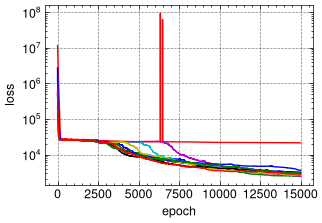

In [12]:
# Loss history
epochs = jnp.arange(N_EPOCHS_ADAM + N_EPOCHS_LBFGS)
fig, axs = plt.subplots(figsize=(3.4, 2.4), constrained_layout=True)
[axs.semilogy(epochs, model.loss_history) for model in models]
axs.set_xlabel("epoch"); axs.set_ylabel("loss")

fig.tight_layout(); fig.show()

In [13]:
ic_rec = jnp.stack([(U_LO + (U_HI - U_LO)
            * jax.vmap(model.net)(XY_NODES_J).reshape(NY, NX, 2, 2)).astype(jnp.float32) for model in models], axis=0)
rel_l1_mask = jnp.sum(jnp.abs(ic_rec - ic_true), axis=(1, 2, 3, 4)) / jnp.sum(jnp.abs(ic_true))
loss_history_mask = jnp.array([models[i].loss_history[-1] for i in range(len(models))])

mask = jnp.argsort(loss_history_mask.reshape(-1))[:N_ENSEMBLES - N_ENSEMBLES_THROW_AWAY]

models = [models[i] for i in mask]
models

In [14]:
print(f'All models training error: {[models[i].loss_history[-1] for i in range(len(models))]}')

All models training error: [2437.39, 2493.42, 2662.99, 2821.05, 2845.67, 2972.84, 3033.32, 3191.35, 3607.1]


In [15]:
print(f'All models with relative L1 error:\n{rel_l1_mask[mask]}')

All models with relative L1 error:
[0.26275802 0.281722   0.27652258 0.20668651 0.40701023 0.22689018
 0.33373392 0.31566867 0.18619797]


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4172648761.py:7: UserWarning: The figure layout has changed to tight
  fig.tight_layout(); fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4172648761.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()


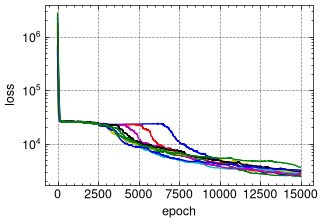

In [16]:
# Loss history
epochs = jnp.arange(N_EPOCHS_ADAM + N_EPOCHS_LBFGS)
fig, axs = plt.subplots(figsize=(3.4, 2.4), constrained_layout=True)
[axs.semilogy(epochs, model.loss_history) for model in models]
axs.set_xlabel("epoch"); axs.set_ylabel("loss")

fig.tight_layout(); fig.show()

data misfit: 12838.4716796875


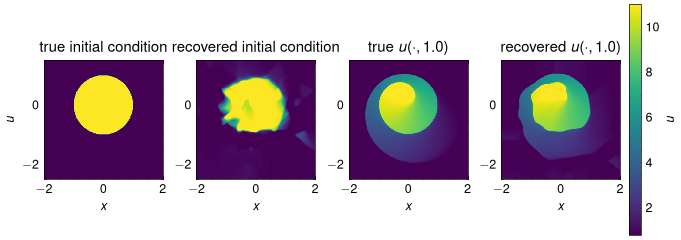

data misfit: 13012.283203125


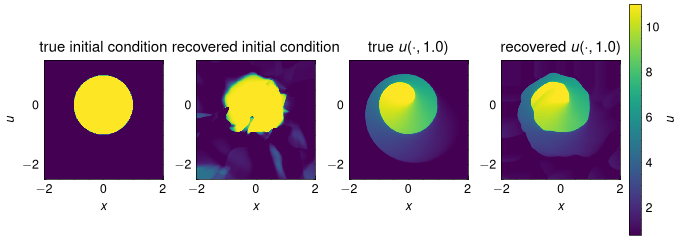

data misfit: 13146.8916015625


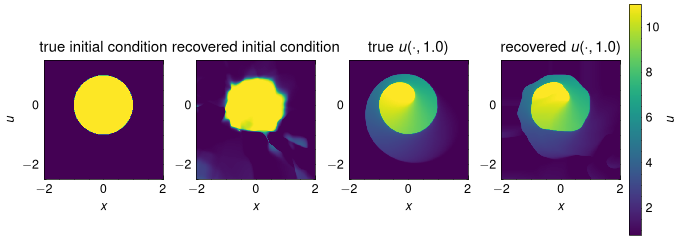

data misfit: 12853.8369140625


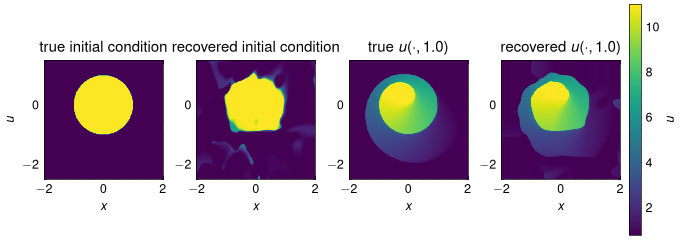

data misfit: 12716.1064453125


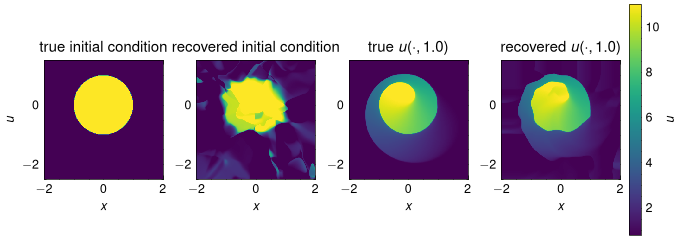

data misfit: 12932.9599609375


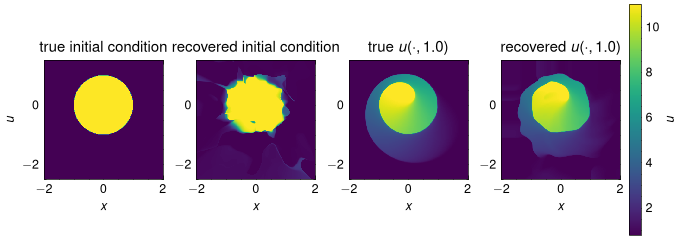

data misfit: 13169.552734375


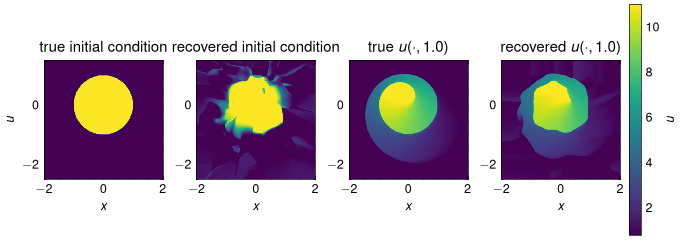

data misfit: 12909.9990234375


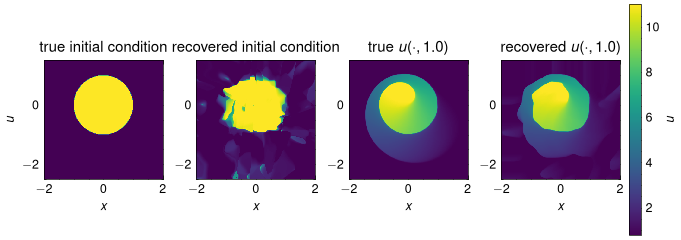

data misfit: 13297.94140625


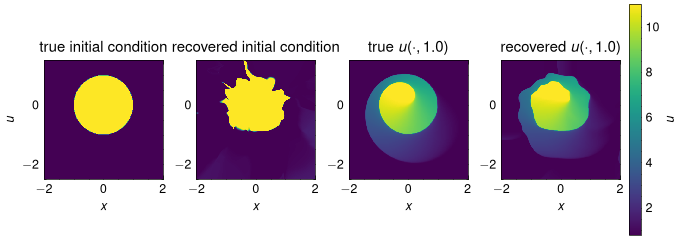

In [17]:
for model in models:
    ic_rec_fine = (U_LO + (U_HI - U_LO)
            * jax.vmap(model.net)(XY_NODES_J_fine).reshape(NY*REFINE_OBSERVATIONS, NX*REFINE_OBSERVATIONS, 2, 2)).astype(jnp.float32)
    d_rec = solver_fine.solve(ic_rec_fine)
    u_ic_rec = jnp.asarray(solver_fine.image(ic_rec_fine))
    u_rec = jnp.asarray(solver_fine.image(d_rec))
    y_rec = u_rec.ravel()[OBS_IDX_fine]

    print("data misfit:", float(jnp.sum((y_obs - y_rec) ** 2) / (2 * NOISE ** 2)))

    fig, axs = plt.subplots(1, 4, figsize=(6.8, 2.4), constrained_layout=True)
    for ax, field, title in ((axs[0], u_init_fine, "true initial condition"),
                            (axs[1], u_ic_rec, "recovered initial condition"),
                            (axs[2], u_sol_fine, f"true $u(\\cdot,{T_END})$"),
                            (axs[3], u_rec, f"recovered $u(\\cdot,{T_END})$")):
        m = ax.pcolormesh(xs_fine, ys_fine, field, cmap="viridis", shading="nearest",
                        vmin=U_LO, vmax=U_HI, rasterized=True)
        ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_title(title)
    axs[0].set_ylabel("$u$")
    fig.colorbar(m, ax=axs, fraction=0.02, pad=0.01, label="$u$")
    plt.show()

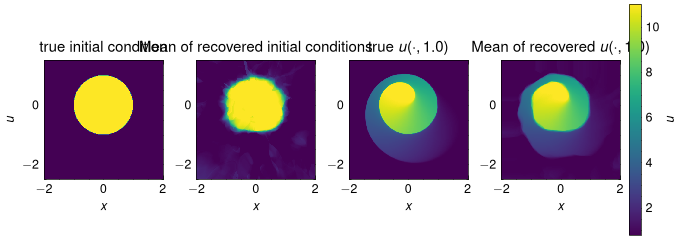

In [18]:
u_ic_rec_vec = []
u_rec_vec = []

for model in models:
    ic_rec = (U_LO + (U_HI - U_LO)
            * jax.vmap(model.net)(XY_NODES_J_fine).reshape(NY*REFINE_OBSERVATIONS, NX*REFINE_OBSERVATIONS, 2, 2)).astype(jnp.float32)
    d_rec = solver_fine.solve(ic_rec)
    u_ic_rec_vec.append(jnp.asarray(solver_fine.image(ic_rec)))
    u_rec_vec.append(jnp.asarray(solver_fine.image(d_rec)))

u_ic_rec_mean = jnp.mean(jnp.asarray(u_ic_rec_vec), axis=0)
u_rec_mean = jnp.mean(jnp.asarray(u_rec_vec), axis=0)

fig, axs = plt.subplots(1, 4, figsize=(6.8, 2.4), constrained_layout=True)
for ax, field, title in ((axs[0], u_init_fine, "true initial condition"),
                        (axs[1], u_ic_rec_mean, "Mean of recovered initial conditions"),
                        (axs[2], u_sol_fine, f"true $u(\\cdot,{T_END})$"),
                        (axs[3], u_rec_mean, f"Mean of recovered $u(\\cdot,{T_END})$")):
    m = ax.pcolormesh(xs_fine, ys_fine, field, cmap="viridis", shading="nearest",
                    vmin=U_LO, vmax=U_HI, rasterized=True)
    ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_title(title)
axs[0].set_ylabel("$u$")
fig.colorbar(m, ax=axs, fraction=0.02, pad=0.01, label="$u$")
plt.show()

In [19]:
rel_l1_of_mean = jnp.sum(jnp.abs(u_ic_rec_mean - u_init_fine)) / jnp.sum(jnp.abs(u_init_fine))
print(f"Relative L1 error of predictive mean of recovered initial conditions: {rel_l1_of_mean:.6f}")

rel_l1_of_mean_u_rec = jnp.sum(jnp.abs(u_rec_mean - u_sol_fine)) / jnp.sum(jnp.abs(u_sol_fine))
print(f"Relative L1 error of predictive mean of recovered solution at t={T_END}: {rel_l1_of_mean_u_rec:.6f}")

Relative L1 error of predictive mean of recovered initial conditions: 0.210688
Relative L1 error of predictive mean of recovered solution at t=1.0: 0.078043


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4086783474.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4086783474.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/4086783474.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


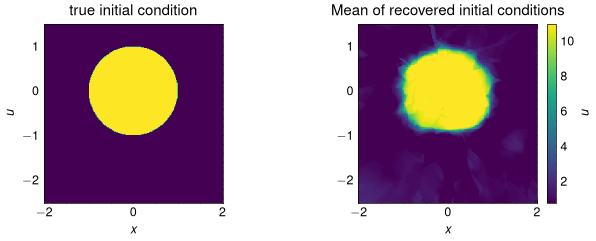

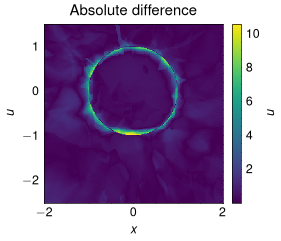

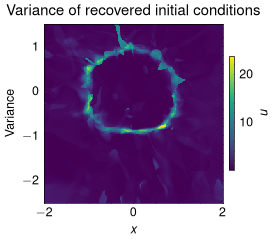

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.4), constrained_layout=True)
for ax, field, title in ((axs[0], u_init_fine, "true initial condition"),
                        (axs[1], u_ic_rec_mean, "Mean of recovered initial conditions")):
    m = ax.pcolormesh(xs_fine, ys_fine, field, cmap="viridis", shading="nearest",
                    vmin=U_LO, vmax=U_HI, rasterized=True)
    ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_title(title)
axs[0].set_ylabel("$u$")
fig.colorbar(m, ax=axs, fraction=0.02, pad=0.01, label="$u$")
fig.show()

fig, ax = plt.subplots(figsize=(6.8, 2.4), constrained_layout=True)
m2 = ax.pcolormesh(xs_fine, ys_fine, jnp.abs(u_init_fine - u_ic_rec_mean), cmap="viridis", shading="nearest", rasterized=True)
ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_title("Absolute difference")
ax.set_ylabel("$u$")
fig.colorbar(m2, ax=ax, fraction=0.02, pad=0.01, label="$u$")
fig.show()

# Variance of the recovered initial conditions
u_ic_rec_var = jnp.var(jnp.asarray(u_ic_rec_vec), axis=0)
fig, axs = plt.subplots(figsize=(3.4, 2.4), constrained_layout=True)
m4 = axs.pcolormesh(xs_fine, ys_fine, u_ic_rec_var, cmap="viridis", shading="nearest", rasterized=True)
axs.set_aspect("equal"); axs.set_xlabel("$x$"); axs.set_title("Variance of recovered initial conditions")
axs.set_ylabel("Variance")
fig.colorbar(m4, ax=axs, fraction=0.02, pad=0.01, label="$u$")
fig.show()

<>:19: SyntaxWarning: invalid escape sequence '\%'
<>:19: SyntaxWarning: invalid escape sequence '\%'
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/665440097.py:19: SyntaxWarning: invalid escape sequence '\%'
  color="C0", alpha=0.2, label="90\% Credible interval"
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/665440097.py:24: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


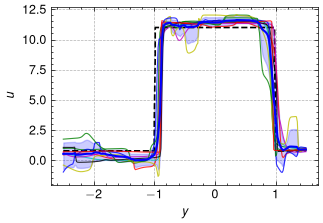

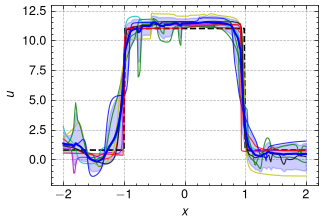

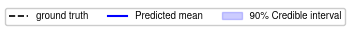

In [21]:
U_ic = jnp.asarray(u_ic_rec_vec)

ix0 = int(jnp.argmin(jnp.abs(xs_fine)))
iy0 = int(jnp.argmin(jnp.abs(ys_fine)))

member_colors = [f"C{i + 1}" for i in range(N_ENSEMBLES)]

for coord, members, ref, line, xlabel in (
        (ys_fine, U_ic[:, :, ix0], u_init_fine[:, ix0], "$x = 0$", "$y$"),
        (xs_fine, U_ic[:, iy0, :], u_init_fine[iy0, :], "$y = 0$", "$x$")):
    fig, axs = plt.subplots(figsize=(6.8/2, 2.4), constrained_layout=True)
    axs.plot(coord, ref, "k--", lw=1.2, label="ground truth")
    for m, c in zip(members, member_colors):
        axs.plot(coord, m, color=c, lw=0.8, alpha=0.8)
    axs.plot(coord, jnp.mean(members, axis=0), color="C0", lw=1.5, label="Predicted mean")
    axs.fill_between(
        coord, jnp.quantile(members, 0.05, axis=0),
        jnp.quantile(members, 0.95, axis=0),
        color="C0", alpha=0.2, label="90\% Credible interval"
    )
    # axs.set_title(f"IC along {line}")
    axs.set_xlabel(xlabel); axs.grid(alpha=0.3)
    axs.set_ylabel("$u$")
    fig.tight_layout()
    fig.savefig(f"out/figures/KPP2D/IC_along_{line.replace(' ', '_')}.pdf", bbox_inches="tight")
    plt.show()

# standalone legend figure (handles from the last axes; both panels have the same entries)
from matplotlib.lines import Line2D
handles, labels = axs.get_legend_handles_labels()
# handles.insert(1, Line2D([], [], color="C1", lw=0.8, alpha=0.8))
fig_leg, axs_leg = plt.subplots(figsize=(6.8/2, 0.5))
axs_leg.axis('off')
fig_leg.legend(handles, labels, loc="center", ncol=4, frameon=True)
fig_leg.tight_layout()
fig_leg.savefig(f"out/figures/KPP2D/IC_along_legend.pdf", bbox_inches="tight")
plt.show()


## Evolution over training

Checkpoints were written every 2 500 gradient steps (`_epoch{step}.csv`). For each of them the ensemble is reloaded and the figures of the previous sections are repeated: mean of the recovered initial conditions, absolute difference to the truth, ensemble variance and the cross sections through the disk centre. The colour scales of the difference and variance plots are shared across epochs so that they can be compared. The last cell plots the relative $L^1$ error of the recovered initial condition against the number of gradient steps -- w.r.t. the true initial condition, not the training loss.

In [22]:
EPOCHS = [2_500, 5_000, 7_500, 10_000, 12_500, 15_000]
seeds_kept = [model.seed for model in models]


def make_model(seed):
    return GSBLBNN(
        width=width, activation=activation, seed=seed,
        optimizer_pretraining=optimizer_pretraining,
        n_epochs_pre_training=N_EPOCHS_ADAM, n_epochs_lbfgs=N_EPOCHS_LBFGS,
        vartheta1=vartheta1, kappa=kappa, c_bias=c_bias,
        shared_bias=True, n_inner=n_inner,
        r=r, beta=beta,
        initializer=initializer,
    )


def recovered_ic(model):
    """(NY, NX, 2, 2) nodal initial condition the network currently represents."""
    return (U_LO + (U_HI - U_LO)
            * jax.vmap(model.net)(XY_NODES_J_fine).reshape(NY*REFINE_OBSERVATIONS, NX*REFINE_OBSERVATIONS, 2, 2)).astype(jnp.float32)


# Fresh model objects for all members, so the `models` of the previous sections keep their
# final state and the discarded members can be shown in the error plot as well.
models_all = [make_model(SEED + i * 1_000) for i in range(N_ENSEMBLES)]
seeds_all = [model.seed for model in models_all]
kept_idx = [seeds_all.index(model.seed) for model in models]     # in the order of `models`

ic_epoch = {}       # epoch -> (N_ENSEMBLES, NY, NX, 2, 2) nodal initial conditions
rel_l1_epoch = {}   # epoch -> (N_ENSEMBLES,) relative L1 error of every member
for epoch in EPOCHS:
    for model in models_all:
        model.load(f'{base_dir}/Ensemble_{model.seed}/_epoch{epoch}')
    ic_epoch[epoch] = jnp.stack([recovered_ic(model) for model in models_all], axis=0)
    rel_l1_epoch[epoch] = (jnp.sum(jnp.abs(ic_epoch[epoch] - ic_true_fine), axis=(1, 2, 3, 4))
                           / jnp.sum(jnp.abs(ic_true)))

# (2*NY, 2*NX) images of the kept members, their mean, variance and difference to the truth
U_ic_epoch = {e: jnp.asarray([solver_fine.image(ic) for ic in ic_epoch[e][jnp.asarray(kept_idx)]])
              for e in EPOCHS}
mean_epoch = {e: jnp.mean(U_ic_epoch[e], axis=0) for e in EPOCHS}
var_epoch = {e: jnp.var(U_ic_epoch[e], axis=0) for e in EPOCHS}
absdiff_epoch = {e: jnp.abs(u_init_fine - mean_epoch[e]) for e in EPOCHS}

for epoch in EPOCHS:
    print(f'{epoch:>6} gradient steps, relative L1 error per member: '
          f'{jnp.round(rel_l1_epoch[epoch], 4)}')

  2500 gradient steps, relative L1 error per member: [22.1787   20.9277   60.115097 29.620499 31.0084   25.002499 16.505
 20.0914   11.9432   13.264299]
  5000 gradient steps, relative L1 error per member: [ 8.1605     7.4041996 54.6548    11.1369    18.733     11.1439
  7.9424996  6.8532     8.2521     4.2307   ]
  7500 gradient steps, relative L1 error per member: [ 3.5683     5.6998997 49.257797   5.9723997  8.6364     4.6096997
  6.5843997  6.6088     5.0403     2.9706   ]
 10000 gradient steps, relative L1 error per member: [ 4.2999     4.3876    44.996597   5.2318     4.8269     4.9866
  5.3037996  5.3708     3.6501     2.5593998]
 12500 gradient steps, relative L1 error per member: [ 5.0698     4.2278    44.157497   4.1507998  4.6201997  5.634
  4.9839997  7.1191998  3.4721     1.9801999]
 15000 gradient steps, relative L1 error per member: [ 5.4021997  4.5305    43.045597   4.4742     4.2683997  6.5428996
  5.1538997  3.0805     3.6492     3.3676   ]


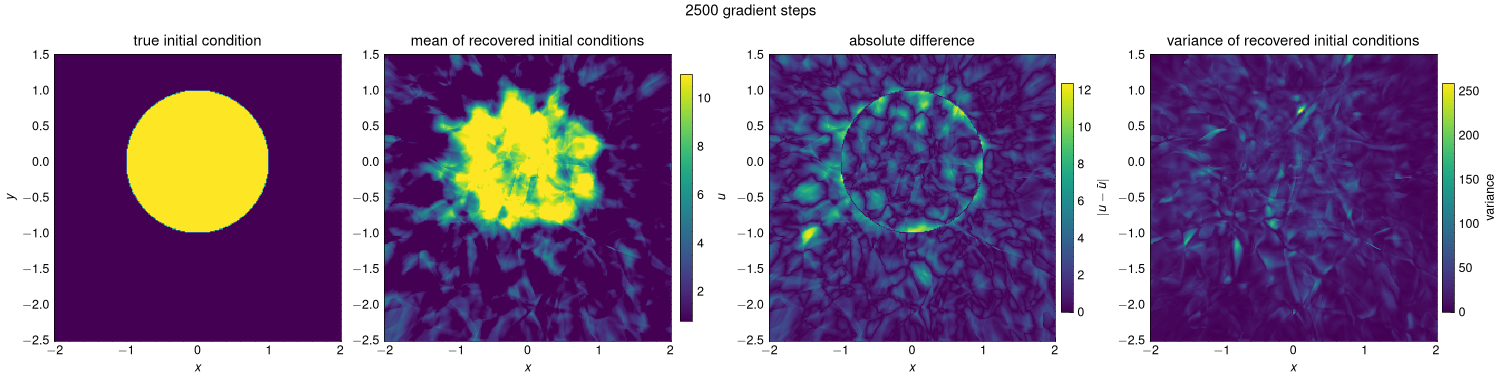

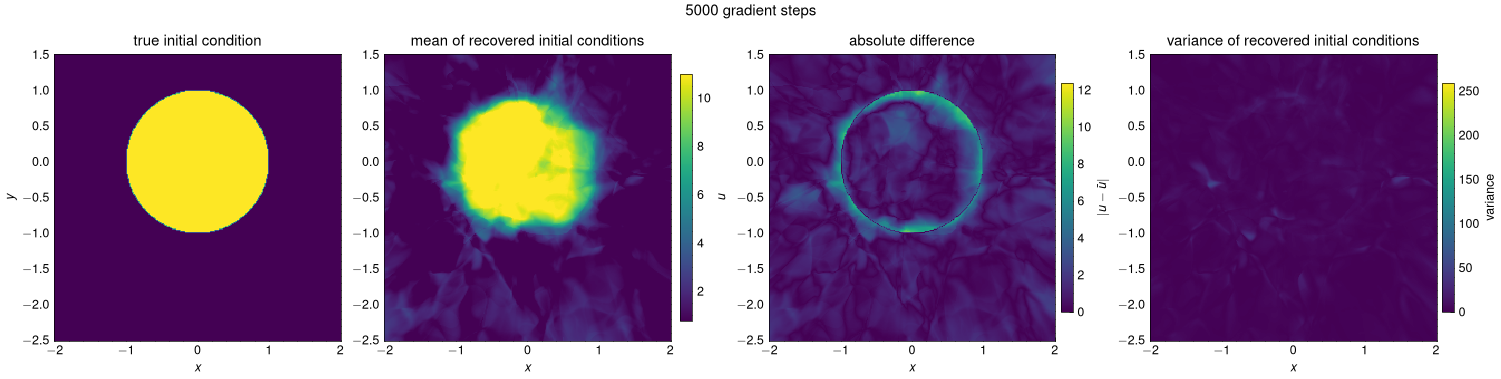

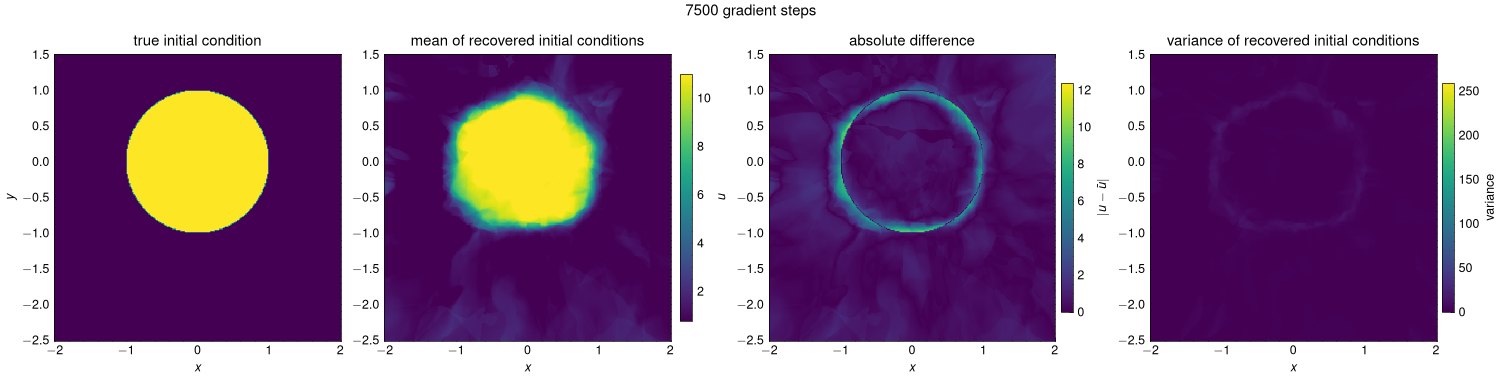

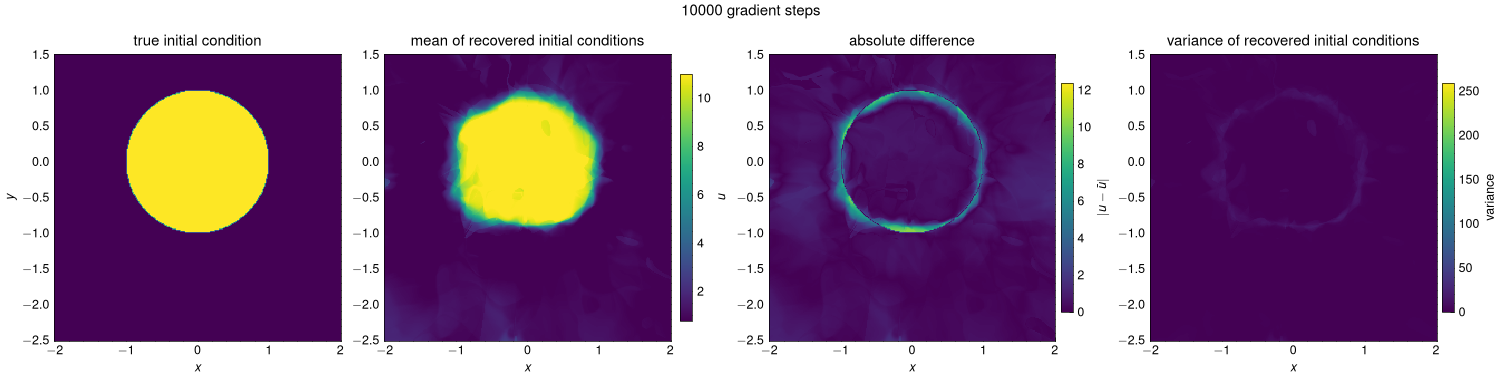

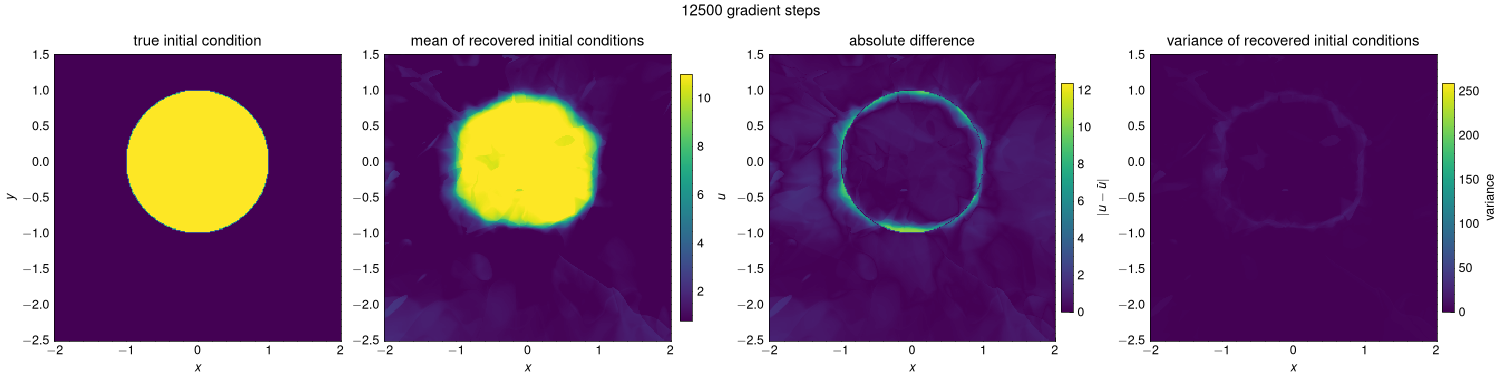

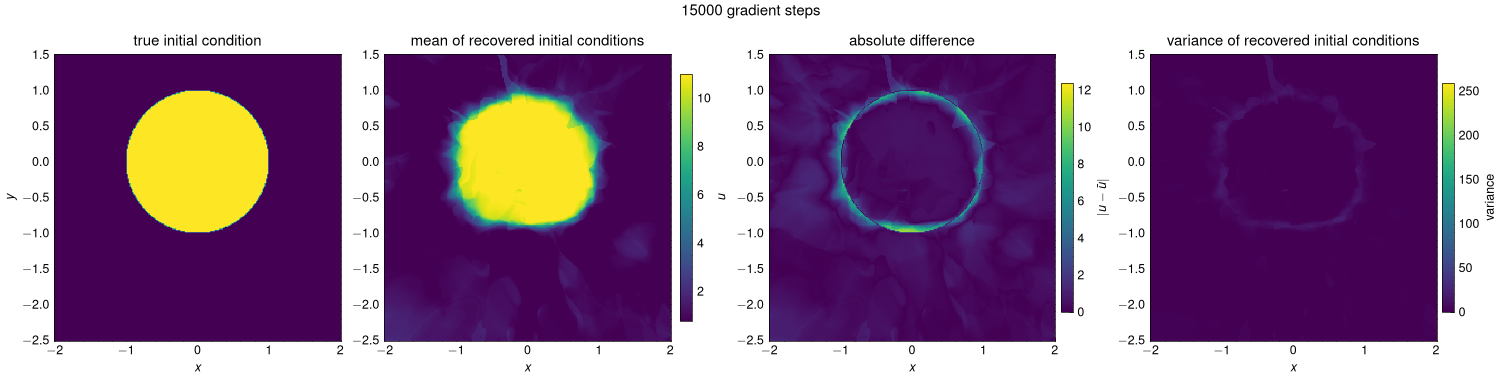

In [23]:
# Mean of the recovered initial conditions, absolute difference to the truth and ensemble
# variance for every checkpoint. Difference and variance share one colour scale across epochs.
vmax_diff = max(float(jnp.max(absdiff_epoch[e])) for e in EPOCHS)
vmax_var = max(float(jnp.max(var_epoch[e])) for e in EPOCHS)

for epoch in EPOCHS:
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), constrained_layout=True)
    fig.suptitle(f'{epoch} gradient steps')
    for ax, field, title in ((axs[0], u_init_fine, 'true initial condition'),
                             (axs[1], mean_epoch[epoch], 'mean of recovered initial conditions')):
        m = ax.pcolormesh(xs_fine, ys_fine, field, cmap='viridis', shading='nearest',
                          vmin=U_LO, vmax=U_HI, rasterized=True)
        ax.set_aspect('equal'); ax.set_xlabel('$x$'); ax.set_title(title)
    axs[0].set_ylabel('$y$')
    fig.colorbar(m, ax=axs[:2], fraction=0.02, pad=0.01, label='$u$')

    m2 = axs[2].pcolormesh(xs_fine, ys_fine, absdiff_epoch[epoch], cmap='viridis', shading='nearest',
                           vmin=0.0, vmax=vmax_diff, rasterized=True)
    axs[2].set_aspect('equal'); axs[2].set_xlabel('$x$'); axs[2].set_title('absolute difference')
    fig.colorbar(m2, ax=axs[2], fraction=0.04, pad=0.01, label='$|u - \\bar{u}|$')

    m3 = axs[3].pcolormesh(xs_fine, ys_fine, var_epoch[epoch], cmap='viridis', shading='nearest',
                           vmin=0.0, vmax=vmax_var, rasterized=True)
    axs[3].set_aspect('equal'); axs[3].set_xlabel('$x$')
    axs[3].set_title('variance of recovered initial conditions')
    fig.colorbar(m3, ax=axs[3], fraction=0.04, pad=0.01, label='variance')
    plt.show()

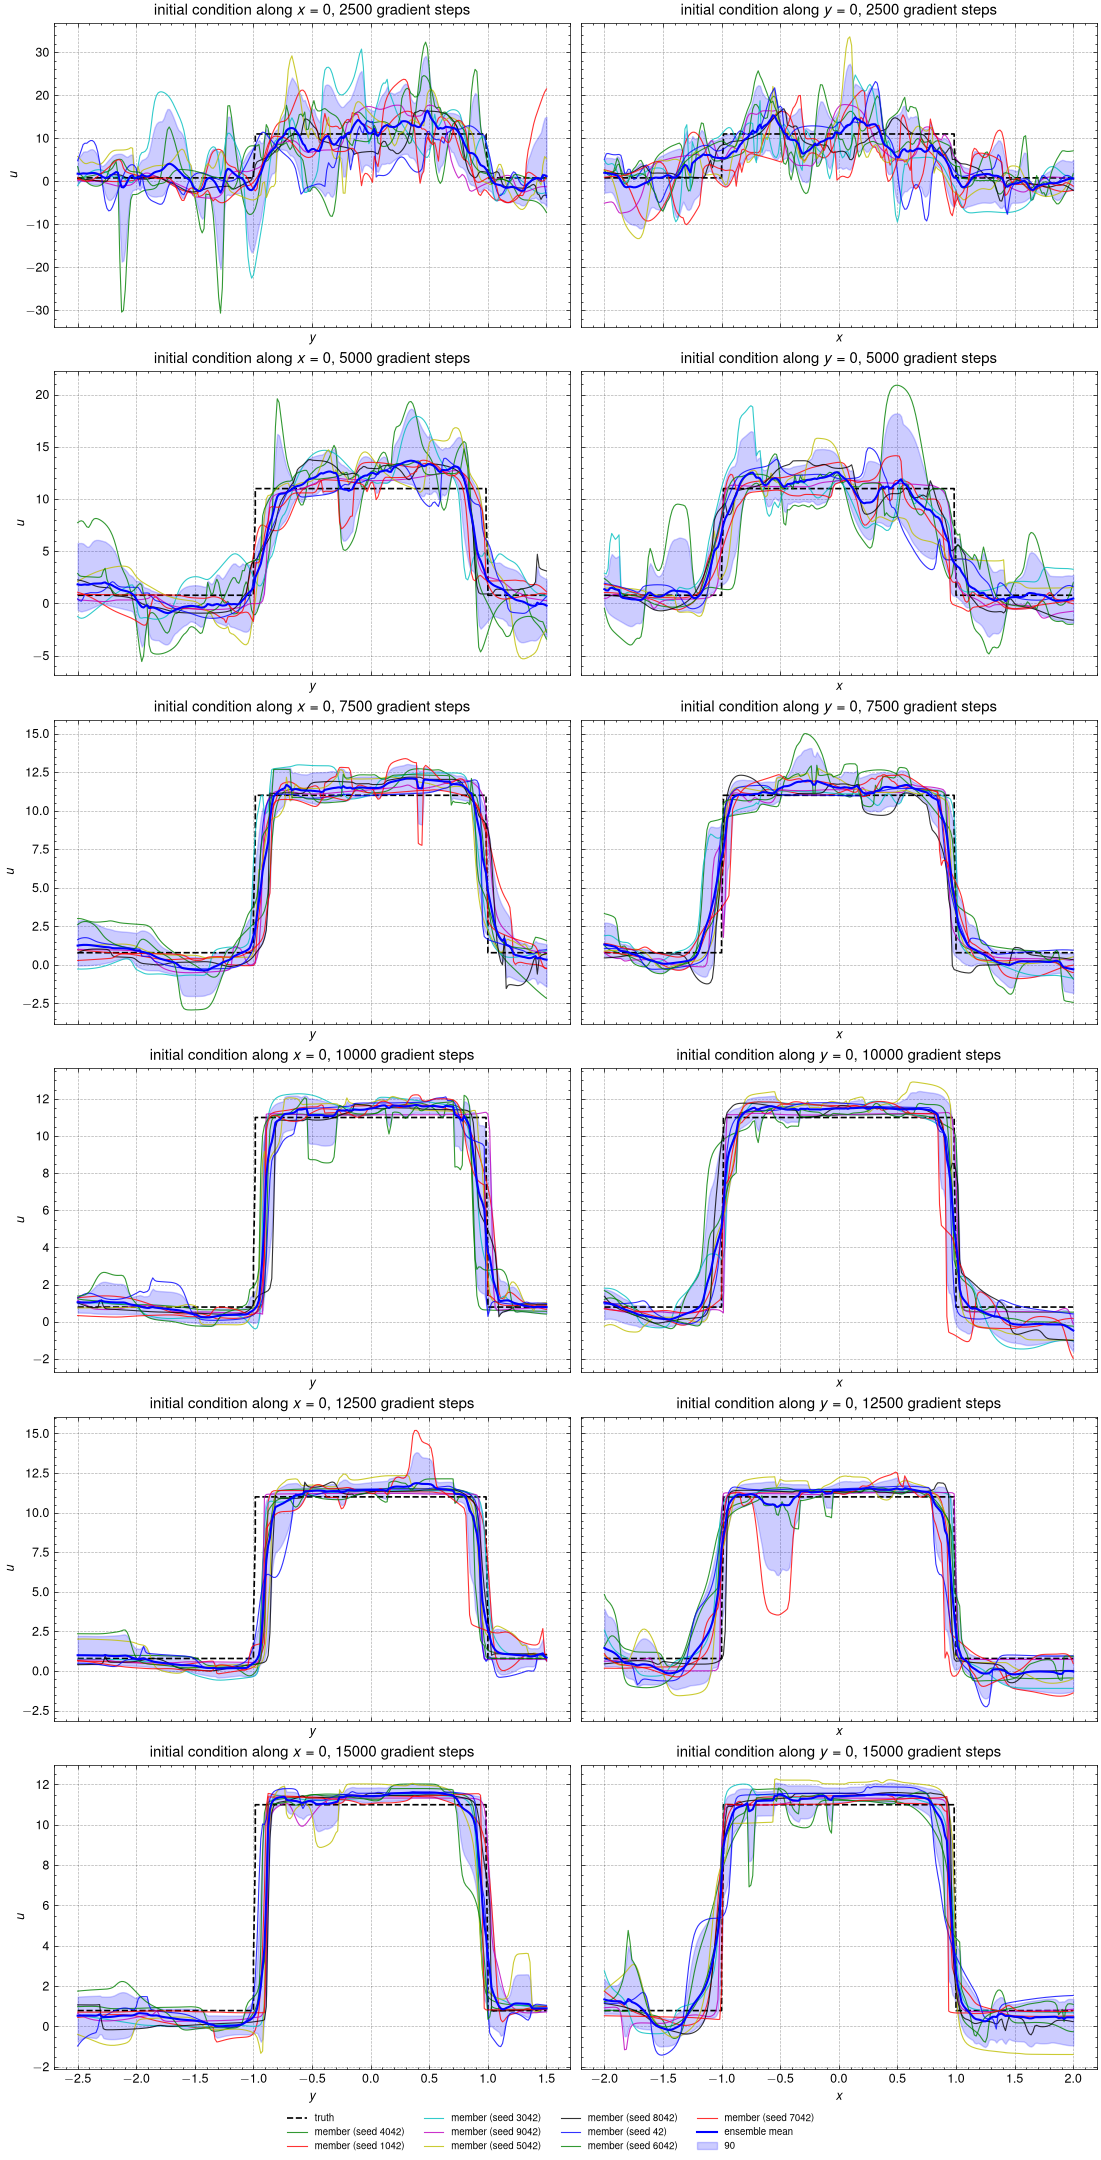

In [24]:
# Cross sections of the recovered initial conditions through the disk centre (x = 0 and y = 0)
# for every checkpoint: kept members, ensemble mean and 90% credibility interval.
fig, axs = plt.subplots(len(EPOCHS), 2, figsize=(11, 3.6 * len(EPOCHS)),
                        sharex='col', sharey='row', constrained_layout=True)
for row, epoch in zip(axs, EPOCHS):
    U = U_ic_epoch[epoch]
    for ax, (coord, members, ref, line, xlabel) in zip(row, (
            (ys_fine, U[:, :, ix0], u_init_fine[:, ix0], '$x = 0$', '$y$'),
            (xs_fine, U[:, iy0, :], u_init_fine[iy0, :], '$y = 0$', '$x$'))):
        ax.plot(coord, ref, 'k--', lw=1.2, label='truth')
        for model, m, c in zip(models, members, member_colors):
            ax.plot(coord, m, color=c, lw=0.8, alpha=0.8, label=f'member (seed {model.seed})')
        ax.plot(coord, jnp.mean(members, axis=0), color='C0', lw=1.5, label='ensemble mean')
        ax.fill_between(coord, jnp.quantile(members, 0.05, axis=0),
                        jnp.quantile(members, 0.95, axis=0),
                        color='C0', alpha=0.2, label='90% CI')
        ax.set_title(f'initial condition along {line}, {epoch} gradient steps')
        ax.set_xlabel(xlabel); ax.grid(alpha=0.3)
    row[0].set_ylabel('$u$')
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, frameon=False)
plt.show()

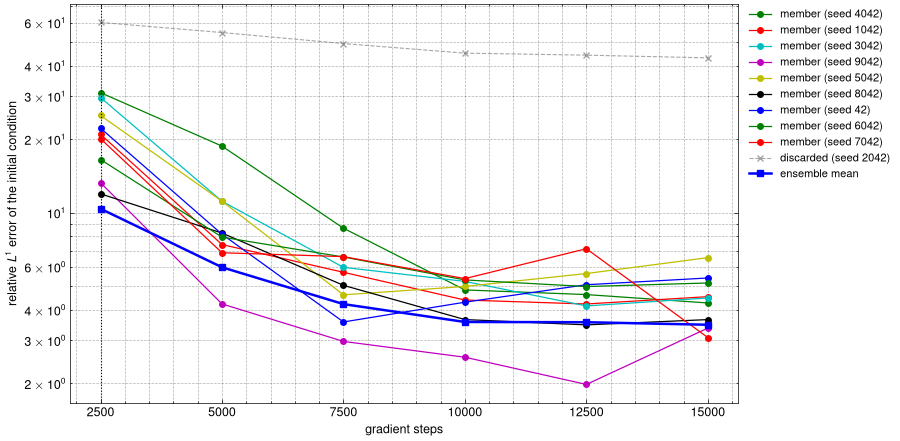

relative L1 error of the ensemble mean: {2500: 10.3778, 5000: 5.9761, 7500: 4.2231, 10000: 3.568, 12500: 3.5599, 15000: 3.476}


In [25]:
# Relative L1 error of the recovered initial condition w.r.t. the TRUE initial condition (not the
# training loss) against the number of gradient steps: kept members coloured, discarded members
# grey, plus the error of the ensemble mean of the kept members. The dotted line marks the switch
# from the pre-training optimizer to L-BFGS.
err_all = jnp.stack([rel_l1_epoch[e] for e in EPOCHS], axis=1)      # (N_ENSEMBLES, len(EPOCHS))
err_mean = jnp.asarray([
    jnp.sum(jnp.abs(jnp.mean(ic_epoch[e][jnp.asarray(kept_idx)], axis=0) - ic_true_fine))
    / jnp.sum(jnp.abs(ic_true)) for e in EPOCHS])

fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
for j, (model, c) in enumerate(zip(models, member_colors)):
    ax.plot(EPOCHS, err_all[kept_idx[j]], 'o-', color=c, lw=0.9, ms=4,
            label=f'member (seed {model.seed})')
for i, seed in enumerate(seeds_all):
    if seed not in seeds_kept:
        ax.plot(EPOCHS, err_all[i], 'x--', color='grey', lw=0.8, ms=5, alpha=0.7,
                label=f'discarded (seed {seed})')
ax.plot(EPOCHS, err_mean, 's-', color='C0', lw=1.8, ms=5, label='ensemble mean')
ax.axvline(N_EPOCHS_ADAM, color='k', ls=':', lw=0.8)
ax.set_yscale('log'); ax.set_xticks(EPOCHS); ax.grid(alpha=0.3, which='both')
ax.set_xlabel('gradient steps'); ax.set_ylabel('relative $L^1$ error of the initial condition')
fig.legend(loc='outside right upper', fontsize=8, frameon=False)
plt.show()

print('relative L1 error of the ensemble mean:',
      {e: round(float(v), 4) for e, v in zip(EPOCHS, err_mean)})

# Paper Plots

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/554855888.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


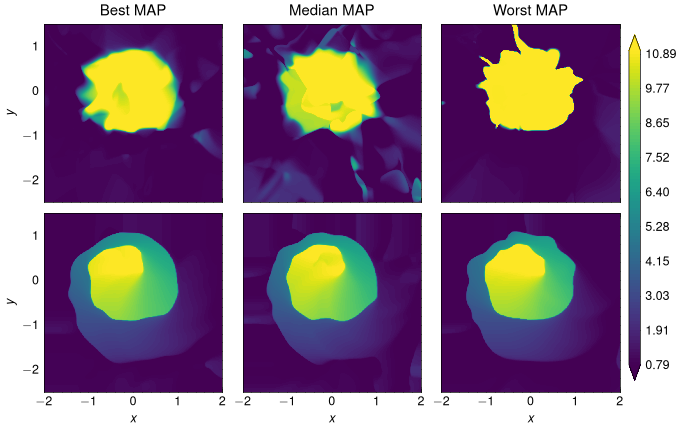

In [26]:
fig, axs = plt.subplots(2, 3, figsize=(6.8, 4.3), sharex=True, sharey=True, constrained_layout=True)

index = [0, int(jnp.median(jnp.linspace(0, len(models), len(models) + 1))), len(models) - 1]
levels = jnp.linspace(U_LO, U_HI, 101)  # same levels in every panel -> one colorbar per row is exact

labels = ['Best MAP', 'Median MAP', 'Worst MAP']
for i_counter, i in enumerate(index):
    model = models[int(i)]
    ic_rec = (U_LO + (U_HI - U_LO)
              * jax.vmap(model.net)(XY_NODES_J_fine).reshape(NY*REFINE_OBSERVATIONS, NX*REFINE_OBSERVATIONS, 2, 2)).astype(jnp.float32)
    d_rec = solver_fine.solve(ic_rec)
    u_ic_rec = jnp.asarray(solver_fine.image(ic_rec))
    u_rec = jnp.asarray(solver_fine.image(d_rec))

    cf = axs[0, i_counter].contourf(
        xs_fine, ys_fine, u_ic_rec,
        cmap='viridis', levels=levels, extend='both', rasterized=True
    )
    axs[0, i_counter].set_aspect('equal')
    axs[0, i_counter].set_title(labels[i_counter])

    axs[1, i_counter].contourf(
        xs_fine, ys_fine, u_rec,
        cmap='viridis', levels=levels, extend='both', rasterized=True
    )
    axs[1, i_counter].set_aspect('equal')

for ax in axs[1]: ax.set_xlabel('$x$')
for ax in axs[:, 0]: ax.set_ylabel('$y$')
fig.colorbar(cf, ax=axs, fraction=0.02, pad=0.01, aspect=30)
if not os.path.exists('out/figures/KPP2D'):
    os.makedirs('out/figures/KPP2D')
fig.savefig(f'out/figures/KPP2D/Ensemble_members.pdf', bbox_inches='tight')
fig.show()

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/1378751630.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


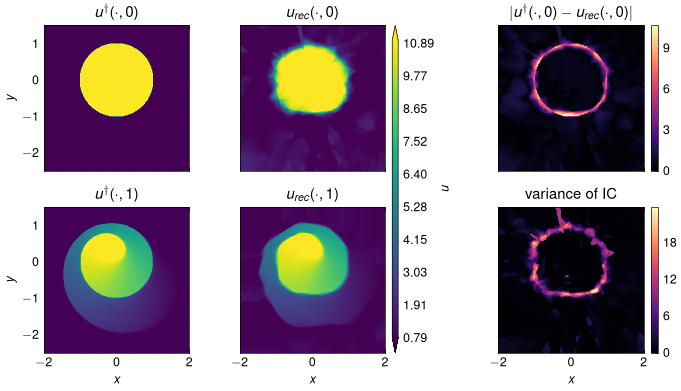

In [27]:
fig, axs = plt.subplots(2, 3, figsize=(6.8, 3.9), sharex=True, sharey=True, constrained_layout=True)
kw_u = dict(cmap='viridis', levels=levels, extend='both', rasterized=True)
kw_e = dict(cmap='magma', levels=100, rasterized=True)  # own auto scale per panel

cf = axs[0, 0].contourf(xs_fine, ys_fine, u_init_fine, **kw_u); axs[0, 0].set_title(f'$u^\\dagger(\\cdot,{0})$')
axs[0, 1].contourf(xs_fine, ys_fine, u_ic_rec_mean, **kw_u); axs[0, 1].set_title(f'$u_{{rec}}(\\cdot,0)$')
ce = axs[0, 2].contourf(xs_fine, ys_fine, jnp.abs(u_init_fine - u_ic_rec_mean), **kw_e); axs[0, 2].set_title('$|u^\\dagger(\\cdot,0) - u_{rec}(\\cdot,0)|$')

axs[1, 0].contourf(xs_fine, ys_fine, u_sol_fine, **kw_u); axs[1, 0].set_title(f'$u^\\dagger(\\cdot,{int(T_END)})$')
axs[1, 1].contourf(xs_fine, ys_fine, u_rec_mean, **kw_u); axs[1, 1].set_title(f'$u_{{rec}}(\\cdot,{int(T_END)})$')
cv = axs[1, 2].contourf(xs_fine, ys_fine, u_ic_rec_var, **kw_e); axs[1, 2].set_title('variance of IC')

for ax in axs.flat: ax.set_aspect('equal')
for ax in axs[1]: ax.set_xlabel('$x$')
for ax in axs[:, 0]: ax.set_ylabel('$y$')

fig.colorbar(cf, ax=axs[:, :2], fraction=0.03, pad=0.01, aspect=55, label='$u$')
for cb in (
    fig.colorbar(ce, ax=axs[0, 2], fraction=0.05, pad=0.02),
    fig.colorbar(cv, ax=axs[1, 2], fraction=0.05, pad=0.02)
):
    cb.locator = ticker.MaxNLocator(4)
    cb.formatter = ticker.ScalarFormatter(useMathText=True)
    cb.formatter.set_powerlimits((-2, 3))
    cb.update_ticks()

fig.savefig('out/figures/KPP2D/Ensemble.pdf', bbox_inches='tight')
fig.show()


In [28]:
coverage_level = jnp.linspace(0.5, 0.99, 50)

U_ic_ens = jnp.asarray(u_ic_rec_vec)   # (n_models, 2*NY*R, 2*NX*R) recovered initial conditions
U_sol_ens = jnp.asarray(u_rec_vec)     # (n_models, 2*NY*R, 2*NX*R) recovered solutions at t = T_END

coverage = {}
for key, ens, truth in (('ic', U_ic_ens, u_init_fine), ('sol', U_sol_ens, u_sol_fine)):
    coverage_vec = []
    for level in coverage_level:
        lo, hi = (1 - level) / 2, 1 - (1 - level) / 2
        q_lo, q_hi = jnp.quantile(ens, lo, axis=0), jnp.quantile(ens, hi, axis=0)
        covered = (truth >= q_lo) & (truth <= q_hi)
        coverage_vec.append(jnp.mean(covered))
    coverage[key] = jnp.asarray(coverage_vec)

for key in coverage:
    print(
        f'{key}: cov(0.50) = {float(coverage[key][0]):.3f}, '
        f'cov(0.90) = {float(coverage[key][40]):.3f}, cov(0.95) = {float(coverage[key][45]):.3f}'
    )


ic: cov(0.50) = 0.410, cov(0.90) = 0.790, cov(0.95) = 0.812
sol: cov(0.50) = 0.292, cov(0.90) = 0.663, cov(0.95) = 0.697


/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_18960/3618202819.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


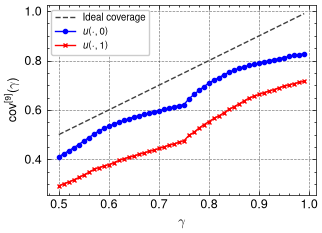

In [29]:
savefig = True

colors = {'ic': 'b', 'sol': 'r'}
marker = {'ic': '-o', 'sol': '-x'}
labels = {'ic': '$u(\\cdot, 0)$', 'sol': f'$u(\\cdot,{int(T_END)})$'}

fig, axs = plt.subplots(figsize=(6.8/2, 2.5))
axs.plot(coverage_level, coverage_level, color='0.25', ls='--', label='Ideal coverage')
for key in coverage:
    axs.plot(coverage_level, coverage[key], marker[key], color=colors[key], label=labels[key])

axs.legend()
axs.set_xlabel('$\\gamma$'); axs.set_ylabel('$\\mathrm{cov}^{[9]}(\\gamma)$')

fig.tight_layout()
if savefig == True:
    fig.savefig('out/figures/KPP2D/Coverage.pdf', bbox_inches='tight')
fig.show()
